# EDA – NYC 311 Street Condition requests (2025)

Data: `street_conditions_2025_labeled.csv` from `data_collection.ipynb`.
Target: `closed_48h` = 1 if the request was closed within 48 hours, 0 otherwise.

In [1]:
import pandas as pd
import numpy as np
import matplotlib
from matplotlib import pylab as plt

In [8]:
df = pd.read_csv(r'C:\Users\jack2\OneDrive\桌面\brown MSDA\data 1030\street_conditions_2025_labeled.csv', low_memory=False)
print(df.shape)

(70322, 38)


In [9]:
print(df.columns)

Index(['unique_key', 'created_date', 'closed_date', 'agency', 'agency_name',
       'complaint_type', 'descriptor', 'incident_zip', 'intersection_street_1',
       'intersection_street_2', 'address_type', 'city', 'facility_type',
       'status', 'resolution_description', 'resolution_action_updated_date',
       'community_board', 'council_district', 'police_precinct', 'borough',
       'x_coordinate_state_plane', 'y_coordinate_state_plane',
       'open_data_channel_type', 'park_facility_name', 'park_borough',
       'latitude', 'longitude', 'location', 'incident_address', 'street_name',
       'cross_street_1', 'cross_street_2', 'descriptor_2', 'location_type',
       'landmark', 'bbl', 'closure_hours', 'closed_48h'],
      dtype='object')


In [10]:
print(df.dtypes)

unique_key                          int64
created_date                       object
closed_date                        object
agency                             object
agency_name                        object
complaint_type                     object
descriptor                         object
incident_zip                      float64
intersection_street_1              object
intersection_street_2              object
address_type                       object
city                               object
facility_type                     float64
status                             object
resolution_description             object
resolution_action_updated_date     object
community_board                    object
council_district                  float64
police_precinct                    object
borough                            object
x_coordinate_state_plane          float64
y_coordinate_state_plane          float64
open_data_channel_type             object
park_facility_name                

In [11]:
print(df.head())

   unique_key         created_date          closed_date agency  \
0    64521713  2025-04-01 00:25:10  2025-04-01 12:14:00    DOT   
1    64514986  2025-04-01 01:24:08  2025-04-02 09:26:00    DOT   
2    64516128  2025-04-01 02:41:23  2025-04-01 09:20:00    DOT   
3    64517547  2025-04-01 02:43:21  2025-04-01 02:43:21    DOT   
4    64523553  2025-04-01 04:28:55  2025-04-01 07:45:00    DOT   

                    agency_name    complaint_type descriptor  incident_zip  \
0  Department of Transportation  Street Condition    Pothole       11377.0   
1  Department of Transportation  Street Condition    Pothole       11429.0   
2  Department of Transportation  Street Condition    Pothole       10035.0   
3  Department of Transportation  Street Condition    Pothole       10035.0   
4  Department of Transportation  Street Condition    Pothole       10013.0   

  intersection_street_1 intersection_street_2  ... incident_address  \
0             45 STREET             50 AVENUE  ...             

### Convert dates

In [12]:
df['created_date'] = pd.to_datetime(df['created_date'])
df['closed_date'] = pd.to_datetime(df['closed_date'])

print(df['created_date'].min(), df['created_date'].max())

2025-01-01 02:27:33 2025-12-31 23:39:14


### New features from the filing time

In [13]:
df['hour'] = df['created_date'].dt.hour
df['month'] = df['created_date'].dt.month
df['day_of_week'] = df['created_date'].dt.day_name()
df['is_weekend'] = df['created_date'].dt.dayofweek >= 5

print(df[['created_date', 'hour', 'month', 'day_of_week', 'is_weekend']].head(10))

         created_date  hour  month day_of_week  is_weekend
0 2025-04-01 00:25:10     0      4     Tuesday       False
1 2025-04-01 01:24:08     1      4     Tuesday       False
2 2025-04-01 02:41:23     2      4     Tuesday       False
3 2025-04-01 02:43:21     2      4     Tuesday       False
4 2025-04-01 04:28:55     4      4     Tuesday       False
5 2025-04-01 04:32:49     4      4     Tuesday       False
6 2025-04-01 05:39:32     5      4     Tuesday       False
7 2025-04-01 06:20:12     6      4     Tuesday       False
8 2025-04-01 06:27:14     6      4     Tuesday       False
9 2025-04-01 06:29:16     6      4     Tuesday       False


In [14]:
# 'Unspecified' borough is really a missing value
print(df['borough'].value_counts())
df['borough'] = df['borough'].replace('Unspecified', np.nan)

borough
QUEENS           25980
BROOKLYN         18375
MANHATTAN        12386
BRONX             6955
STATEN ISLAND     6494
Unspecified        132
Name: count, dtype: int64


## 1. Data quality

In [15]:
# missing values per column
print(df.isna().sum())

unique_key                            0
created_date                          0
closed_date                        3475
agency                                0
agency_name                           0
complaint_type                        0
descriptor                            0
incident_zip                        749
intersection_street_1             24352
intersection_street_2             24331
address_type                          0
city                              10900
facility_type                     70322
status                                0
resolution_description               15
resolution_action_updated_date       12
community_board                       0
council_district                  19796
police_precinct                       0
borough                             132
x_coordinate_state_plane          19598
y_coordinate_state_plane          19591
open_data_channel_type                0
park_facility_name                    0
park_borough                          0


In [16]:
# missing values as a fraction, only the columns we plan to use
cols = ['closed_date', 'descriptor', 'borough', 'incident_zip', 'latitude', 'longitude',
        'address_type', 'open_data_channel_type']
print(df[cols].isna().mean().round(3))

closed_date               0.049
descriptor                0.000
borough                   0.002
incident_zip              0.011
latitude                  0.279
longitude                 0.279
address_type              0.000
open_data_channel_type    0.000
dtype: float64


In [17]:
print('duplicate unique_key:', df['unique_key'].duplicated().sum())
print('duplicate rows:', df.duplicated().sum())

duplicate unique_key: 0
duplicate rows: 0


In [18]:
# where are the missing coordinates? check by address type
df['location_missing'] = df['latitude'].isna()

count_matrix = df.groupby(['address_type', 'location_missing']).size().unstack()
print(count_matrix)

location_missing    False    True 
address_type                      
ADDRESS           27739.0      9.0
BLOCKFACE           163.0  19476.0
INTERSECTION      22663.0    116.0
PLACE                72.0      NaN
PLACENAME            26.0      NaN
UNRECOGNIZED         58.0      NaN


In [19]:
# closure times that look strange
print('closure_hours == 0:', (df['closure_hours'] == 0).sum())
print('closure_hours > 1 year:', (df['closure_hours'] > 24*365).sum())
print('closure_hours missing:', df['closure_hours'].isna().sum())

closure_hours == 0: 3276
closure_hours > 1 year: 13
closure_hours missing: 3475


In [20]:
# which channel do the 0-hour closures come from?
print(df[df['closure_hours'] == 0]['open_data_channel_type'].value_counts())

open_data_channel_type
UNKNOWN    3276
Name: count, dtype: int64


In [21]:
print(df[df['closure_hours'] == 0][['created_date', 'closed_date', 'descriptor', 'status']].head(10))

           created_date         closed_date descriptor  status
3   2025-04-01 02:43:21 2025-04-01 02:43:21    Pothole  Closed
5   2025-04-01 04:32:49 2025-04-01 04:32:49    Pothole  Closed
12  2025-04-01 07:08:31 2025-04-01 07:08:31    Pothole  Closed
39  2025-04-01 09:08:55 2025-04-01 09:08:55    Pothole  Closed
41  2025-04-01 09:10:15 2025-04-01 09:10:15    Pothole  Closed
44  2025-04-01 09:17:03 2025-04-01 09:17:03    Pothole  Closed
72  2025-04-01 10:46:38 2025-04-01 10:46:38    Pothole  Closed
79  2025-04-01 11:20:28 2025-04-01 11:20:28    Pothole  Closed
83  2025-04-01 11:37:54 2025-04-01 11:37:54    Pothole  Closed
122 2025-04-01 14:03:51 2025-04-01 14:03:51    Pothole  Closed


## 2. Target variable

In [22]:
print(df['closed_48h'].value_counts())
print(df['closed_48h'].value_counts(normalize=True))

closed_48h
1    44355
0    25967
Name: count, dtype: int64
closed_48h
1    0.630741
0    0.369259
Name: proportion, dtype: float64


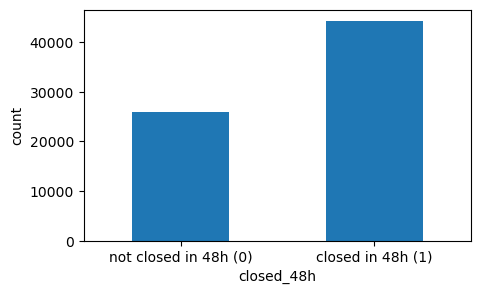

In [23]:
plt.figure(figsize=(5,3))
df['closed_48h'].value_counts().sort_index().plot.bar()
plt.xticks([0, 1], ['not closed in 48h (0)', 'closed in 48h (1)'], rotation=0)
plt.ylabel('count')
plt.show()

In [24]:
print(df['closure_hours'].describe())

count    66847.000000
mean        69.127957
std        230.147526
min          0.000000
25%         17.518194
50%         26.006389
75%         69.034722
max      12122.434444
Name: closure_hours, dtype: float64


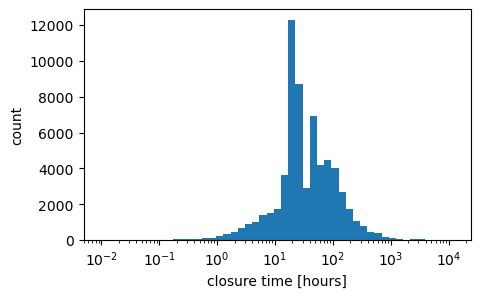

In [25]:
# closure_hours is very skewed (minutes to more than a year) -> log bins and log x-axis
plt.figure(figsize=(5,3))
df[df['closure_hours'] > 0]['closure_hours'].plot.hist(bins=np.logspace(np.log10(0.01), np.log10(df['closure_hours'].max()), 50))
plt.semilogx()
plt.xlabel('closure time [hours]')
plt.ylabel('count')
plt.show()

## 3. Each feature on its own

### Categorical features

borough
QUEENS           25980
BROOKLYN         18375
MANHATTAN        12386
BRONX             6955
STATEN ISLAND     6494
Name: count, dtype: int64


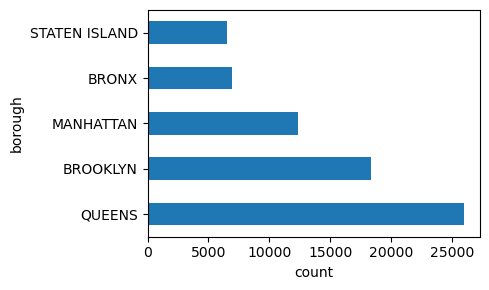

In [26]:
print(df['borough'].value_counts())

plt.figure(figsize=(5,3))
df['borough'].value_counts().plot.barh()
plt.xlabel('count')
plt.ylabel('borough')
plt.tight_layout()
plt.show()

open_data_channel_type
UNKNOWN    41288
ONLINE     15842
PHONE      13191
OTHER          1
Name: count, dtype: int64


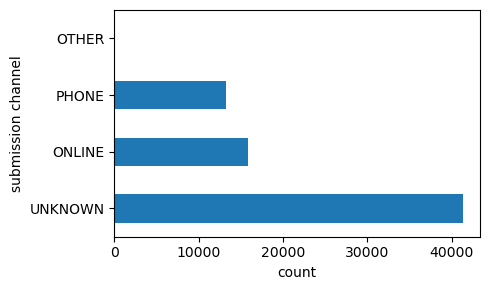

In [27]:
print(df['open_data_channel_type'].value_counts())

plt.figure(figsize=(5,3))
df['open_data_channel_type'].value_counts().plot.barh()
plt.xlabel('count')
plt.ylabel('submission channel')
plt.tight_layout()
plt.show()

address_type
ADDRESS         27748
INTERSECTION    22779
BLOCKFACE       19639
PLACE              72
UNRECOGNIZED       58
PLACENAME          26
Name: count, dtype: int64


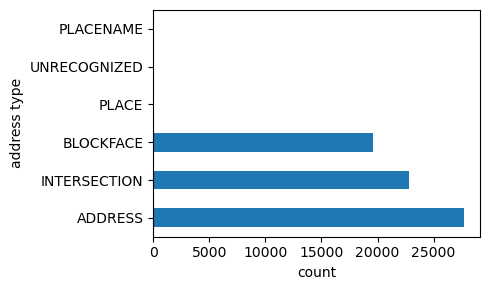

In [28]:
print(df['address_type'].value_counts())

plt.figure(figsize=(5,3))
df['address_type'].value_counts().plot.barh()
plt.xlabel('count')
plt.ylabel('address type')
plt.tight_layout()
plt.show()

In [29]:
print(df['descriptor'].value_counts())
print('number of descriptors:', df['descriptor'].nunique())
print('descriptors with < 100 requests:', (df['descriptor'].value_counts() < 100).sum())

descriptor
Pothole                           38430
Cave-in                            9647
Defective Hardware                 5490
Blocked - Construction             4245
Failed Street Repair               3487
Rough, Pitted or Cracked Roads     3121
Plate Condition - Noisy            2927
Plate Condition - Shifted           622
Dumpster - Construction Waste       584
Line/Marking - After Repaving       507
Line/Marking - Faded                386
Wear & Tear                         291
Crash Cushion Defect                225
Guard Rail - Street                 106
Unsafe Worksite                      66
Plate Condition - Open               65
Plate Condition - Anti-Skid          53
Depression Maintenance               31
Defacement                           20
Hummock                              18
Strip Paving                          1
Name: count, dtype: int64
number of descriptors: 21
descriptors with < 100 requests: 7


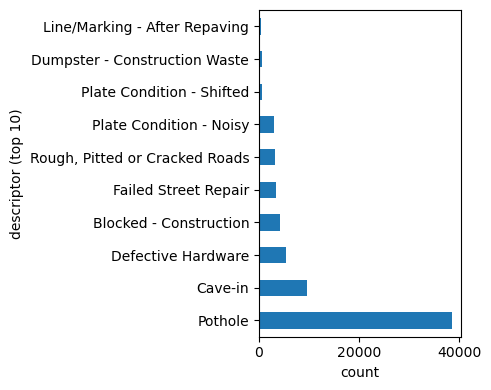

In [34]:
plt.figure(figsize=(5,4))
df['descriptor'].value_counts().head(10).plot.barh()
plt.xlabel('count')
plt.ylabel('descriptor (top 10)')
plt.tight_layout()
plt.show()

Potholes are more than half of all requests. 7 descriptors have fewer than 100 requests, we could group them into "Other" later.

### Ordinal features (keep the right order)

day_of_week
Monday       11794
Tuesday      12544
Wednesday    12570
Thursday     11623
Friday        9569
Saturday      5811
Sunday        6411
Name: count, dtype: int64


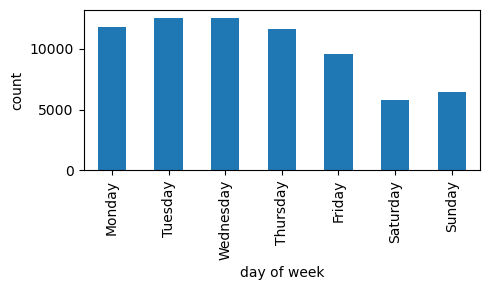

In [35]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

print(df['day_of_week'].value_counts().reindex(day_order))

plt.figure(figsize=(5,3))
df['day_of_week'].value_counts().reindex(day_order).plot.bar()
plt.ylabel('count')
plt.xlabel('day of week')
plt.tight_layout()
plt.show()

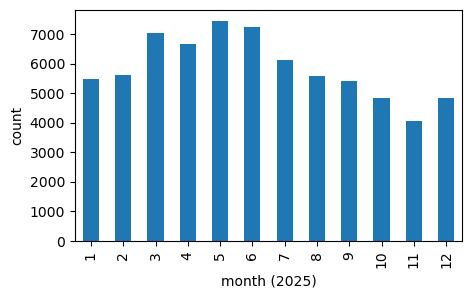

In [36]:
plt.figure(figsize=(5,3))
df['month'].value_counts().sort_index().plot.bar()
plt.ylabel('count')
plt.xlabel('month (2025)')
plt.show()

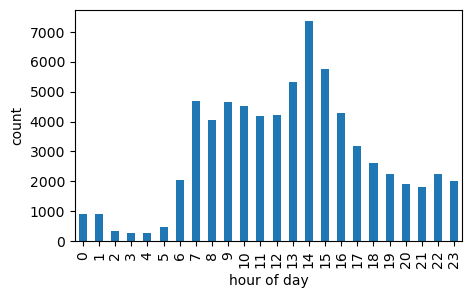

In [37]:
plt.figure(figsize=(5,3))
df['hour'].value_counts().sort_index().plot.bar()
plt.ylabel('count')
plt.xlabel('hour of day')
plt.show()

### Continuous features

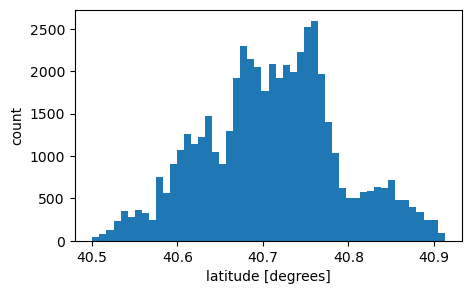

In [38]:
plt.figure(figsize=(5,3))
df['latitude'].plot.hist(bins=50)
plt.xlabel('latitude [degrees]')
plt.ylabel('count')
plt.show()

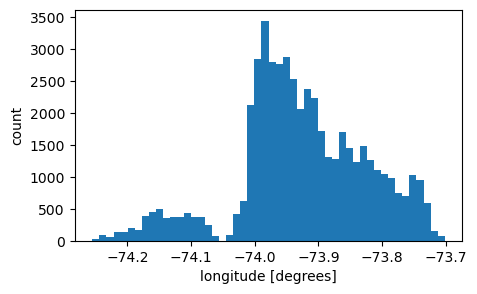

In [39]:
plt.figure(figsize=(5,3))
df['longitude'].plot.hist(bins=50)
plt.xlabel('longitude [degrees]')
plt.ylabel('count')
plt.show()

## 4. Features vs. target

### Categorical features vs. target

closed_48h            0         1
borough                          
BRONX          0.610496  0.389504
BROOKLYN       0.386939  0.613061
MANHATTAN      0.285322  0.714678
QUEENS         0.354927  0.645073
STATEN ISLAND  0.277949  0.722051


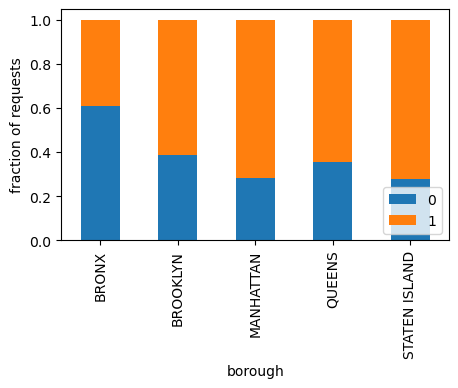

In [40]:
count_matrix = df.groupby(['borough', 'closed_48h']).size().unstack()
count_matrix_norm = count_matrix.div(count_matrix.sum(axis=1), axis=0)
print(count_matrix_norm)

count_matrix_norm.plot(kind='bar', stacked=True, figsize=(5,3))
plt.ylabel('fraction of requests')
plt.legend(loc=4)
plt.show()

closed_48h                     0         1
open_data_channel_type                    
ONLINE                  0.493625  0.506375
OTHER                        NaN  1.000000
PHONE                   0.518081  0.481919
UNKNOWN                 0.274002  0.725998


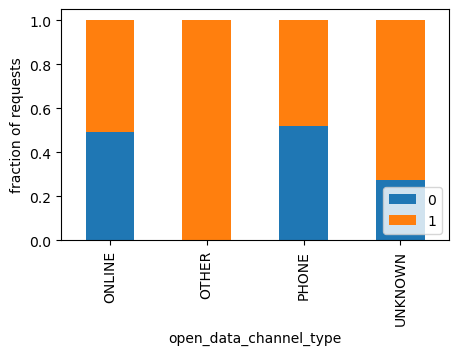

In [41]:
count_matrix = df.groupby(['open_data_channel_type', 'closed_48h']).size().unstack()
count_matrix_norm = count_matrix.div(count_matrix.sum(axis=1), axis=0)
print(count_matrix_norm)

count_matrix_norm.plot(kind='bar', stacked=True, figsize=(5,3))
plt.ylabel('fraction of requests')
plt.legend(loc=4)
plt.show()

closed_48h           0         1
address_type                    
ADDRESS       0.412895  0.587105
BLOCKFACE     0.338612  0.661388
INTERSECTION  0.341191  0.658809
PLACE         0.652778  0.347222
PLACENAME     0.230769  0.769231
UNRECOGNIZED  0.603448  0.396552


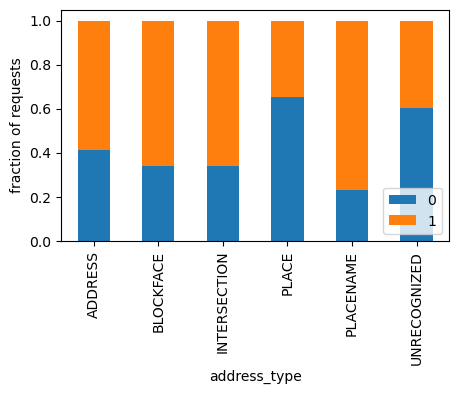

In [42]:
count_matrix = df.groupby(['address_type', 'closed_48h']).size().unstack()
count_matrix_norm = count_matrix.div(count_matrix.sum(axis=1), axis=0)
print(count_matrix_norm)

count_matrix_norm.plot(kind='bar', stacked=True, figsize=(5,3))
plt.ylabel('fraction of requests')
plt.legend(loc=4)
plt.show()

closed_48h                             0         1
descriptor                                        
Blocked - Construction          0.507892  0.492108
Cave-in                         0.557168  0.442832
Defective Hardware              0.458652  0.541348
Dumpster - Construction Waste   0.525685  0.474315
Failed Street Repair            0.570691  0.429309
Line/Marking - After Repaving   1.000000       NaN
Plate Condition - Noisy         0.327639  0.672361
Plate Condition - Shifted       0.360129  0.639871
Pothole                         0.254723  0.745277
Rough, Pitted or Cracked Roads  0.340916  0.659084


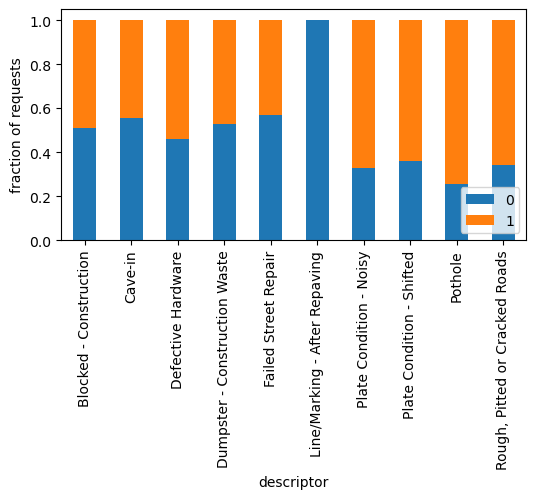

In [43]:
top10 = df['descriptor'].value_counts().head(10).index

count_matrix = df[df['descriptor'].isin(top10)].groupby(['descriptor', 'closed_48h']).size().unstack()
count_matrix_norm = count_matrix.div(count_matrix.sum(axis=1), axis=0)
print(count_matrix_norm)

count_matrix_norm.plot(kind='bar', stacked=True, figsize=(6,3))
plt.ylabel('fraction of requests')
plt.legend(loc=4)
plt.show()

closed_48h          0         1
day_of_week                    
Monday       0.267170  0.732830
Tuesday      0.259805  0.740195
Wednesday    0.273827  0.726173
Thursday     0.334165  0.665835
Friday       0.708329  0.291671
Saturday     0.588883  0.411117
Sunday       0.316799  0.683201


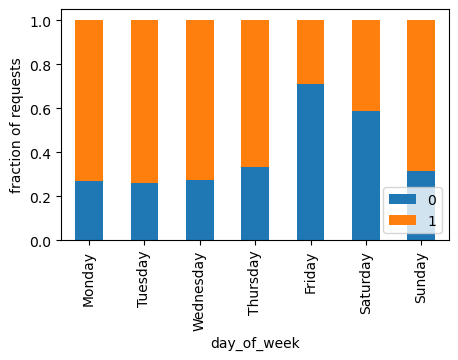

In [44]:
count_matrix = df.groupby(['day_of_week', 'closed_48h']).size().unstack().reindex(day_order)
count_matrix_norm = count_matrix.div(count_matrix.sum(axis=1), axis=0)
print(count_matrix_norm)

count_matrix_norm.plot(kind='bar', stacked=True, figsize=(5,3))
plt.ylabel('fraction of requests')
plt.legend(loc=4)
plt.show()

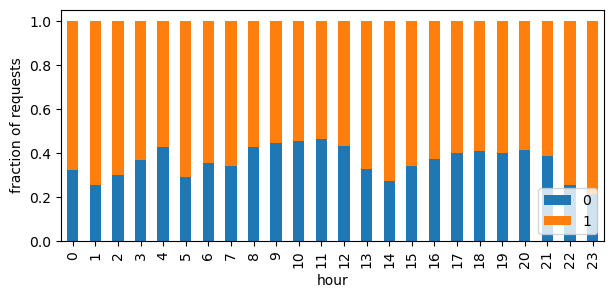

In [45]:
count_matrix = df.groupby(['hour', 'closed_48h']).size().unstack()
count_matrix_norm = count_matrix.div(count_matrix.sum(axis=1), axis=0)

count_matrix_norm.plot(kind='bar', stacked=True, figsize=(7,3))
plt.ylabel('fraction of requests')
plt.legend(loc=4)
plt.show()

In [46]:
print(df['closed_date'].dt.day_name().value_counts().reindex(day_order))
print(df['closed_date'].dt.day_name().value_counts(normalize=True).reindex(day_order).round(3))

closed_date
Monday       12998
Tuesday      14007
Wednesday    13709
Thursday     11783
Friday       11825
Saturday      1354
Sunday        1171
Name: count, dtype: int64
closed_date
Monday       0.194
Tuesday      0.210
Wednesday    0.205
Thursday     0.176
Friday       0.177
Saturday     0.020
Sunday       0.018
Name: proportion, dtype: float64


### Continuous features vs. target

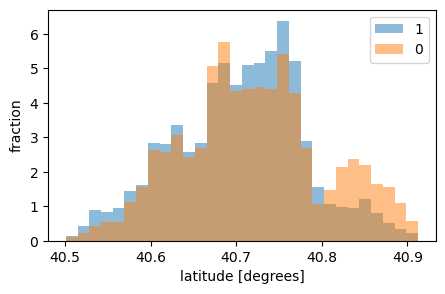

In [47]:
categories = df['closed_48h'].unique()
bin_range = (df['latitude'].min(), df['latitude'].max())

plt.figure(figsize=(5,3))
for c in categories:
    plt.hist(df[df['closed_48h'] == c]['latitude'], alpha=0.5, label=c, range=bin_range, bins=30, density=True)
plt.legend()
plt.ylabel('fraction')
plt.xlabel('latitude [degrees]')
plt.show()

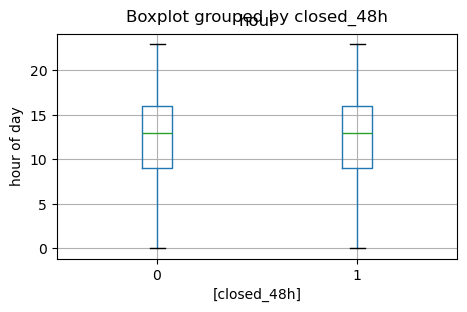

In [48]:
df[['hour', 'closed_48h']].boxplot(by='closed_48h', figsize=(5,3))
plt.ylabel('hour of day')
plt.show()

### Continuous vs. continuous

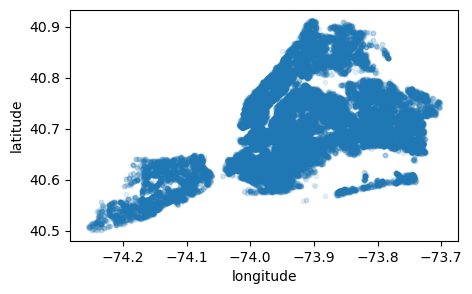

In [49]:
df.plot.scatter('longitude','latitude',figsize=(5,3),alpha=0.1,s=10)
plt.show()

## 5. Time structure

In [50]:
print(df.groupby('month')['closed_48h'].agg(['size', 'mean']))

       size      mean
month                
1      5474  0.776580
2      5622  0.728033
3      7032  0.691553
4      6659  0.650999
5      7449  0.590146
6      7242  0.621790
7      6137  0.547336
8      5590  0.552057
9      5411  0.607466
10     4829  0.591841
11     4049  0.556928
12     4828  0.635667


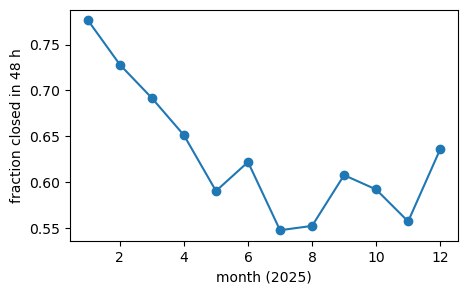

In [51]:
plt.figure(figsize=(5,3))
df.groupby('month')['closed_48h'].mean().plot(marker='o')
plt.xlabel('month (2025)')
plt.ylabel('fraction closed in 48 h')
plt.show()

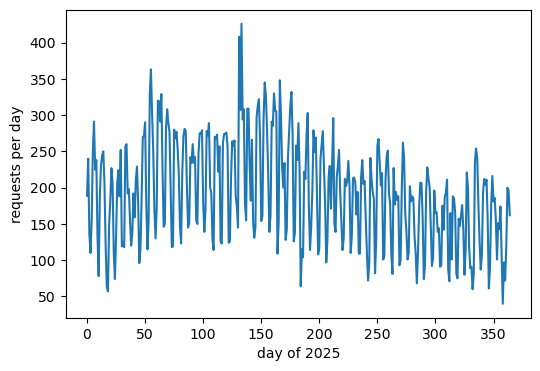

In [52]:
daily = df.groupby(df['created_date'].dt.date).size()

plt.figure(figsize=(6,4))
plt.plot(daily.values)
plt.xlabel('day of 2025')
plt.ylabel('requests per day')
plt.show()

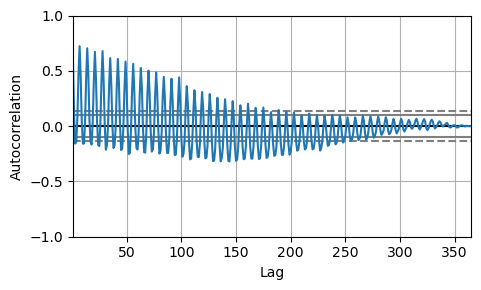

In [53]:
plt.figure(figsize=(5,3))
pd.plotting.autocorrelation_plot(daily)
plt.tight_layout()
plt.show()

## 6. Figures for the report

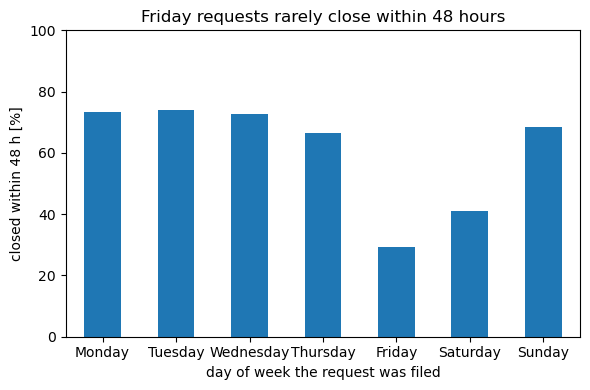

In [56]:
# Figure 1: day of week
by_day = df.groupby('day_of_week')['closed_48h'].mean().reindex(day_order) * 100

plt.figure(figsize=(6,4))
by_day.plot.bar()
plt.title('Friday requests rarely close within 48 hours')
plt.xlabel('day of week the request was filed')
plt.ylabel('closed within 48 h [%]')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(r'C:\Users\jack2\OneDrive\桌面\brown MSDA\data 1030/figures/fig1_day_of_week.png', dpi=200)
plt.show()

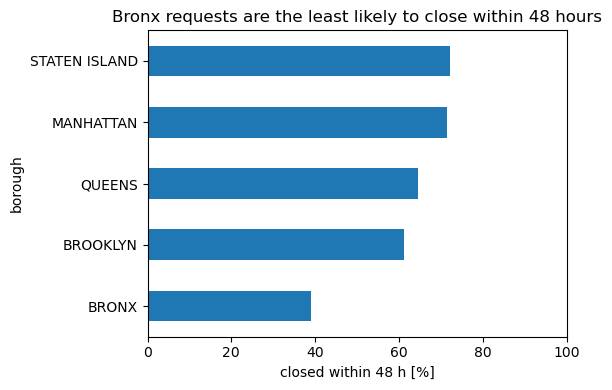

In [59]:
# Figure 2: borough
by_borough = df.groupby('borough')['closed_48h'].mean().sort_values() * 100

plt.figure(figsize=(6,4))
by_borough.plot.barh()
plt.title('Bronx requests are the least likely to close within 48 hours')
plt.xlabel('closed within 48 h [%]')
plt.ylabel('borough')
plt.xlim(0, 100)
plt.tight_layout()
plt.savefig(r'C:\Users\jack2\OneDrive\桌面\brown MSDA\data 1030/figures/fig2_borough.png', dpi=200)
plt.show()

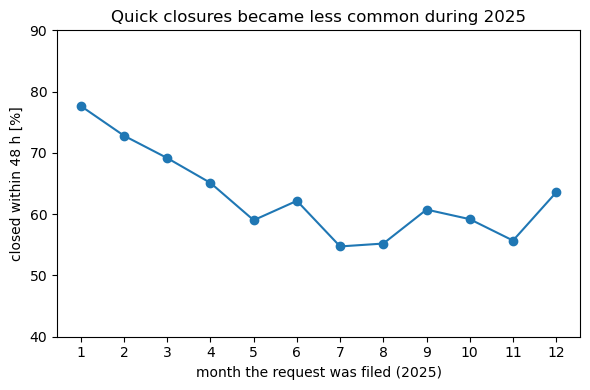

In [60]:
# Figure 3: month
by_month = df.groupby('month')['closed_48h'].mean() * 100

plt.figure(figsize=(6,4))
plt.plot(by_month.index, by_month.values, marker='o')
plt.title('Quick closures became less common during 2025')
plt.xlabel('month the request was filed (2025)')
plt.ylabel('closed within 48 h [%]')
plt.xticks(range(1, 13))
plt.ylim(40, 90)
plt.tight_layout()
plt.savefig(r'C:\Users\jack2\OneDrive\桌面\brown MSDA\data 1030/figures//fig3_month.png', dpi=200)
plt.show()